In [4]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense
from tensorflow.keras.utils import to_categorical

In [5]:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2054s 12us/step
Training data: (50000, 32, 32, 3)
Testing data: (10000, 32, 32, 3)


In [6]:
x_train = x_train / 255.0
x_test = x_test / 255.0

y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

In [7]:
model = Sequential([
    Flatten(input_shape=(32, 32, 3)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(10, activation='softmax')
])

C:\Users\noyal\anaconda3\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [8]:
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.fit(x_train, y_train, epochs=5, batch_size=64)

Epoch 1/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.3068 - loss: 1.9103
Epoch 2/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.3825 - loss: 1.7227
Epoch 3/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.4114 - loss: 1.6455
Epoch 4/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.4277 - loss: 1.5964
Epoch 5/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.4419 - loss: 1.5570


In [9]:
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4389 - loss: 1.5545
Test Loss: 1.554472804069519
Test Accuracy: 43.88999938964844 %


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
Predicted Label: Cat
Actual Label: Cat


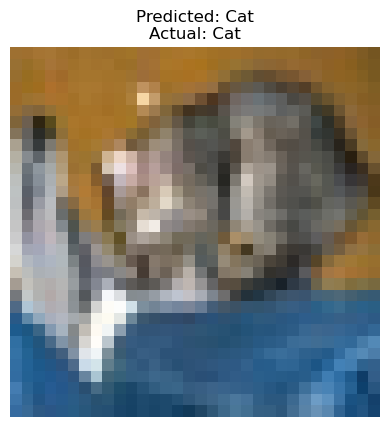

In [12]:
classes = ['Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
           'Dog', 'Frog', 'Horse', 'Ship', 'Truck']

i = 0
prediction = model.predict(x_test[i:i+1])

predicted = np.argmax(prediction)
actual = np.argmax(y_test[i])

print("Predicted Label:", classes[predicted])
print("Actual Label:", classes[actual])

plt.imshow(x_test[i])
plt.title("Predicted: " + classes[predicted] +
          "\nActual: " + classes[actual])
plt.axis('off')
plt.show()